# Практическая работа № 8. Градиентный бустинг и сравнение моделей

**Цель:** обучить градиентный бустинг, подобрать `learning_rate` и `max_depth`, применить раннюю остановку и сравнить результат со случайным лесом и логистической регрессией.

Используется тот же Telco Customer Churn, что и в ПР-7. Тестовая часть отделяется один раз и не участвует в выборе параметров. Для ранней остановки из тренировочной части выделяется отдельная валидационная выборка.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
DATA_CANDIDATES = [
    Path("data/raw/Churn.csv"),
    Path("../data/raw/Churn.csv"),
    Path("../../data/raw/Churn.csv"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Не найден data/raw/Churn.csv. Запустите ноутбук из корня репозитория или папки notebooks/practice_8.")

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
y = df["Churn"].map({"Yes": 1, "No": 0})
X = pd.get_dummies(df.drop(columns=["customerID", "Churn"]), drop_first=True, dtype=int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print(f"Датасет: {df.shape[0]} строк, {X.shape[1]} признаков после one-hot кодирования")
print(f"Train/test: {len(X_train_full)}/{len(X_test)}; train-fit/validation: {len(X_fit)}/{len(X_val)}")
print("Test не используется при подборе гиперпараметров.")

Датасет: 7043 строк, 30 признаков после one-hot кодирования
Train/test: 5634/1409; train-fit/validation: 4507/1127
Test не используется при подборе гиперпараметров.


## Подбор гиперпараметров и ранняя остановка

Проверяем несколько значений скорости обучения и глубины деревьев. Для каждой модели отслеживаем `log-loss` на validation по последовательным стадиям бустинга. Число деревьев выбираем на стадии с минимальным validation `log-loss`; если он не улучшается 30 стадий подряд, дальнейший просмотр кривой не нужен. В `scikit-learn` `GradientBoostingClassifier` не имеет callback для отдельной validation выборки: поэтому сначала вычисляется staged-кривая до лимита, а затем итоговая модель переобучается на полном train с выбранным числом деревьев.

In [2]:
LEARNING_RATES = [0.03, 0.05, 0.1, 0.2]
MAX_DEPTHS = [2, 3, 4]
MAX_TREES = 600
PATIENCE = 30

grid_rows = []
tuning_start = perf_counter()
for learning_rate in LEARNING_RATES:
    for max_depth in MAX_DEPTHS:
        candidate = GradientBoostingClassifier(
            n_estimators=MAX_TREES,
            learning_rate=learning_rate,
            max_depth=max_depth,
            random_state=RANDOM_STATE,
        )
        candidate.fit(X_fit, y_fit)

        best_loss = np.inf
        best_iteration = 0
        best_accuracy = 0.0
        best_macro_f1 = 0.0
        rounds_without_improvement = 0
        for iteration, probabilities in enumerate(candidate.staged_predict_proba(X_val), start=1):
            validation_loss = log_loss(y_val, probabilities, labels=[0, 1])
            predictions = (probabilities[:, 1] >= 0.5).astype(int)
            if validation_loss < best_loss - 1e-7:
                best_loss = validation_loss
                best_iteration = iteration
                best_accuracy = accuracy_score(y_val, predictions)
                best_macro_f1 = f1_score(y_val, predictions, average="macro")
                rounds_without_improvement = 0
            else:
                rounds_without_improvement += 1
            if rounds_without_improvement >= PATIENCE:
                break

        grid_rows.append({
            "learning_rate": learning_rate,
            "max_depth": max_depth,
            "best_n_estimators": best_iteration,
            "validation_log_loss": best_loss,
            "validation_accuracy": best_accuracy,
            "validation_macro_f1": best_macro_f1,
        })

tuning_seconds = perf_counter() - tuning_start
grid_results = pd.DataFrame(grid_rows).sort_values(
    ["validation_accuracy", "validation_macro_f1"], ascending=False
).reset_index(drop=True)
display(grid_results)

best_params = grid_results.iloc[0]
best_learning_rate = float(best_params["learning_rate"])
best_max_depth = int(best_params["max_depth"])
best_n_estimators = int(best_params["best_n_estimators"])
print(f"Выбранные параметры: learning_rate={best_learning_rate}, max_depth={best_max_depth}, n_estimators={best_n_estimators}")
print(f"Перебор занял {tuning_seconds:.2f} с")

,learning_rate,max_depth,best_n_estimators,validation_log_loss,validation_accuracy,validation_macro_f1
0,0.20,2,48,0.410805,0.814552,0.735545
1,0.03,2,343,0.411085,0.814552,0.734069
2,0.20,4,27,0.412504,0.813665,0.734646
3,0.05,2,192,0.410950,0.813665,0.733911
4,0.10,2,91,0.411985,0.812777,0.732272
5,0.03,3,215,0.412248,0.812777,0.730007
6,0.03,4,208,0.413133,0.810115,0.729592
7,0.10,3,96,0.412333,0.810115,0.728843
8,0.05,3,150,0.412447,0.809228,0.727197
9,0.20,3,87,0.413150,0.808341,0.727814


Выбранные параметры: learning_rate=0.2, max_depth=2, n_estimators=48
Перебор занял 75.63 с


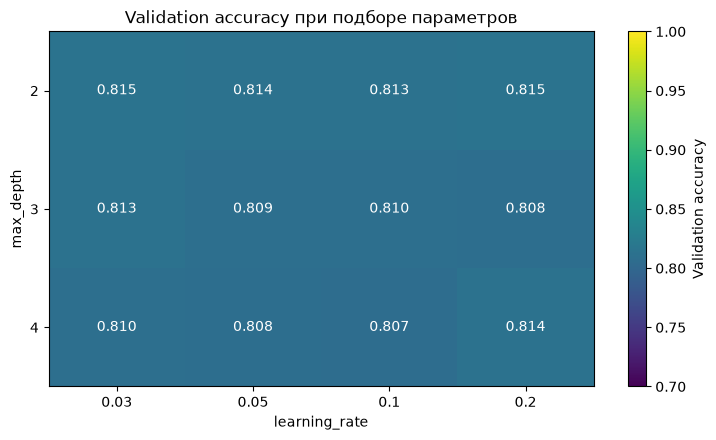

,mean_validation_accuracy,mean_best_trees
learning_rate,,
0.03,0.812482,255.333333
0.05,0.810411,145.666667
0.10,0.810115,89.000000
0.20,0.812186,54.000000


Уменьшение learning_rate обычно требует большего числа деревьев; validation качество в этом эксперименте меняется немонотонно.


In [3]:
# Сводим validation accuracy в матрицу для тепловой карты.
accuracy_grid = grid_results.pivot(
    index="max_depth", columns="learning_rate", values="validation_accuracy"
).sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4.5))
image = ax.imshow(accuracy_grid.values, cmap="viridis", vmin=0.70, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(accuracy_grid.columns)), [str(value) for value in accuracy_grid.columns])
ax.set_yticks(range(len(accuracy_grid.index)), [str(value) for value in accuracy_grid.index])
ax.set_xlabel("learning_rate")
ax.set_ylabel("max_depth")
ax.set_title("Validation accuracy при подборе параметров")
for row in range(accuracy_grid.shape[0]):
    for col in range(accuracy_grid.shape[1]):
        ax.text(col, row, f"{accuracy_grid.iloc[row, col]:.3f}", ha="center", va="center", color="white")
fig.colorbar(image, ax=ax, label="Validation accuracy")
fig.tight_layout()
plt.show()

learning_rate_trend = grid_results.groupby("learning_rate").agg(
    mean_validation_accuracy=("validation_accuracy", "mean"),
    mean_best_trees=("best_n_estimators", "mean"),
)
display(learning_rate_trend)
print("Уменьшение learning_rate обычно требует большего числа деревьев; validation качество в этом эксперименте меняется немонотонно.")

## Сравнение моделей на одном разбиении

Итоговый бустинг обучается на всём train с числом деревьев, выбранным по validation. Для сравнения переобучаем дерево и Random Forest из ПР-7, а также логистическую регрессию на том же train. Дополнительно смотрим `macro-F1`, precision и recall класса оттока, поскольку классы несбалансированы.

In [4]:
models = []

def evaluate_model(name, model, params):
    train_predictions = model.predict(X_train_full)
    test_predictions = model.predict(X_test)
    return {
        "Модель": name,
        "Параметры": params,
        "Accuracy train": accuracy_score(y_train_full, train_predictions),
        "Accuracy test": accuracy_score(y_test, test_predictions),
        "F1-macro train": f1_score(y_train_full, train_predictions, average="macro"),
        "F1-macro test": f1_score(y_test, test_predictions, average="macro"),
        "Precision churn test": precision_score(y_test, test_predictions, zero_division=0),
        "Recall churn test": recall_score(y_test, test_predictions, zero_division=0),
        "Время обучения, с": fit_seconds,
    }

boosting = GradientBoostingClassifier(
    n_estimators=best_n_estimators,
    learning_rate=best_learning_rate,
    max_depth=best_max_depth,
    random_state=RANDOM_STATE,
)
start = perf_counter(); boosting.fit(X_train_full, y_train_full); fit_seconds = perf_counter() - start
models.append(evaluate_model("Gradient Boosting", boosting, f"learning_rate={best_learning_rate}, max_depth={best_max_depth}, n_estimators={best_n_estimators}"))

tree = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5)
start = perf_counter(); tree.fit(X_train_full, y_train_full); fit_seconds = perf_counter() - start
models.append(evaluate_model("Decision Tree (PR-7)", tree, "max_depth=5"))

forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
start = perf_counter(); forest.fit(X_train_full, y_train_full); fit_seconds = perf_counter() - start
models.append(evaluate_model("Random Forest (PR-7)", forest, "n_estimators=100"))

logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
start = perf_counter(); logistic.fit(X_train_full, y_train_full); fit_seconds = perf_counter() - start
models.append(evaluate_model("Logistic Regression", logistic, "StandardScaler, max_iter=2000"))

comparison = pd.DataFrame(models).sort_values("Accuracy test", ascending=False).reset_index(drop=True)
display(comparison.round(4))

,Модель,Параметры,Accuracy train,Accuracy test,F1-macro train,F1-macro test,Precision churn test,Recall churn test,"Время обучения, с"
0,Logistic Regression,"StandardScaler, max_iter=2000",0.8060,0.8070,0.7365,0.7405,0.6584,0.5668,0.0365
1,Gradient Boosting,"learning_rate=0.2, max_depth=2, n_estimators=48",0.8142,0.7999,0.7430,0.7222,0.6586,0.5107,0.3746
2,Decision Tree (PR-7),max_depth=5,0.8012,0.7942,0.7345,0.7239,0.6296,0.5455,0.0189
3,Random Forest (PR-7),n_estimators=100,0.9980,0.7864,0.9975,0.7050,0.6237,0.4920,0.2423


## Выводы

- Проверяйте не только accuracy, но и macro-F1/recall оттока: модель может хорошо распознавать класс `No` и пропускать часть ушедших клиентов.
- Сравнивайте `learning_rate` вместе с выбранным числом деревьев: меньший шаг обычно требует больше итераций. Небольшие изменения validation качества могут не оправдать значительного увеличения времени.
- Итоговую модель выбираем по тестовому качеству и времени обучения. Перебор параметров учитывается отдельно, поскольку он заметно увеличивает общие вычислительные затраты.
- Результаты ПР-7 для этого разбиения: Decision Tree accuracy около 0.7942, Random Forest около 0.7878. Небольшие расхождения при повторном запуске возможны из-за версии библиотек.